
# TEXT CLASSIFICATION AND SENTIMENT ANALYSIS



### Tasks
### Data Cleaning:
Remove duplicates, handle missing reviews if any, preprocess text (lowercasing, stopwords removal).



In [1]:
# IMPORTS
import pandas as pd
import numpy as np
import string
import nltk
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt
from wordcloud import WordCloud

In [2]:
# 1. DATA LOADING & CLEANING
# ---------------------------------------------
df = pd.read_csv("amazonreviews.tsv", sep="\t")

# Remove duplicates & missing rows
df = df.drop_duplicates()
df = df.dropna(subset=["label", "review"])

print("Dataset Shape:", df.shape)
print(df["label"].value_counts())
print(df.isnull().sum())

Dataset Shape: (10000, 2)
label
neg    5097
pos    4903
Name: count, dtype: int64
label     0
review    0
dtype: int64


In [3]:
# 2. TEXT PREPROCESSING
# ---------------------------------------------
nltk.download("stopwords")
stop_words = set(stopwords.words("english"))

def preprocess_text(text):
    text = str(text).lower()
    text = text.translate(str.maketrans('', '', string.punctuation))  # remove punctuation
    tokens = [word for word in text.split() if word not in stop_words]
    return " ".join(tokens)

df["cleaned_review"] = df["review"].apply(preprocess_text)


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


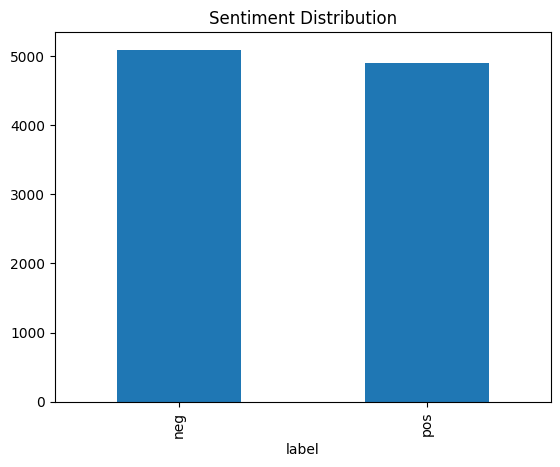

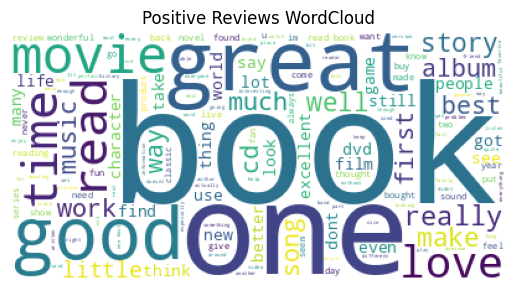

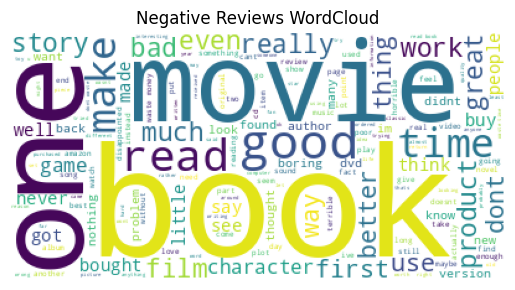

In [4]:
# 3. EXPLORATORY ANALYSIS (Word Clouds + Distribution)
# ---------------------------------------------
df["label"].value_counts().plot(kind="bar", title="Sentiment Distribution")
plt.show()

# positive word cloud
pos_text = " ".join(df[df["label"] == "pos"]["cleaned_review"])
plt.imshow(WordCloud(background_color="white").generate(pos_text))
plt.title("Positive Reviews WordCloud")
plt.axis("off")
plt.show()
# negative word cloud
neg_text = " ".join(df[df["label"] == "neg"]["cleaned_review"])
plt.imshow(WordCloud(background_color="white").generate(neg_text))
plt.title("Negative Reviews WordCloud")
plt.axis("off")
plt.show()

In [5]:
# 4. FEATURE EXTRACTION (TF-IDF)
# ---------------------------------------------
tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(df["cleaned_review"])

# Encode labels (pos=1, neg=0)
y = df["label"].map({"pos": 1, "neg": 0}).values

# train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [6]:
# 5. MODEL DEVELOPMENT
# ---------------------------------------------

# 5A. Logistic Regression
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)
pred_lr = log_reg.predict(X_test)

In [7]:
# 5B. Support Vector Machine (SVM)
svm_model = SVC(kernel="linear")
svm_model.fit(X_train, y_train)
pred_svm = svm_model.predict(X_test)

In [8]:
# 5C. Neural Network (MLPClassifier)
nn_model = MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=20)
nn_model.fit(X_train, y_train)
pred_nn = nn_model.predict(X_test)

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


In [9]:
# 6. MODEL VALIDATION & RESULTS
# ---------------------------------------------
print("\n--- Logistic Regression ---")
print("Accuracy:", accuracy_score(y_test, pred_lr))
print(classification_report(y_test, pred_lr))

print("\n--- SVM Classifier ---")
print("Accuracy:", accuracy_score(y_test, pred_svm))
print(classification_report(y_test, pred_svm))

print("\n--- Neural Network ---")
print("Accuracy:", accuracy_score(y_test, pred_nn))
print(classification_report(y_test, pred_nn))


--- Logistic Regression ---
Accuracy: 0.8455
              precision    recall  f1-score   support

           0       0.86      0.84      0.85      1037
           1       0.84      0.85      0.84       963

    accuracy                           0.85      2000
   macro avg       0.85      0.85      0.85      2000
weighted avg       0.85      0.85      0.85      2000


--- SVM Classifier ---
Accuracy: 0.8515
              precision    recall  f1-score   support

           0       0.86      0.86      0.86      1037
           1       0.85      0.85      0.85       963

    accuracy                           0.85      2000
   macro avg       0.85      0.85      0.85      2000
weighted avg       0.85      0.85      0.85      2000


--- Neural Network ---
Accuracy: 0.83
              precision    recall  f1-score   support

           0       0.83      0.84      0.84      1037
           1       0.83      0.82      0.82       963

    accuracy                           0.83      2000
  